### Test for the new way of instantiate the Tan channel

In [1]:
# To get the parent path for the notebook
import os
import sys

parent_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))

if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

%matplotlib widget

import numpy as np
import plotly.io as pio
from scipy.constants import c, pi

pio.renderers.default = (
    "notebook_connected"  # 'browser' for avoid error but shown in the browser
)

from channels.tx2ris2rx.tang_general_channel import tang_general_channel
from components.antenna import Antenna
from components.ris import RIS
from utils.utils import *

In [2]:
# Create RIS
f = 28e9
lam = c / f

ris = RIS(
    center=[0, 0, 0],
    boresight="z",
    Ncol=32,
    Nrow=32,
    delta_h=lam / 2,
    delta_v=lam / 2,
    dx=0.47 * lam,
    dy=0.47 * lam,
    fc=f,
    radiation_factor=1,
    phase_shifts_dict={"0": 0, "1": pi},
    att_dict={"0": 1, "1": 1},
)

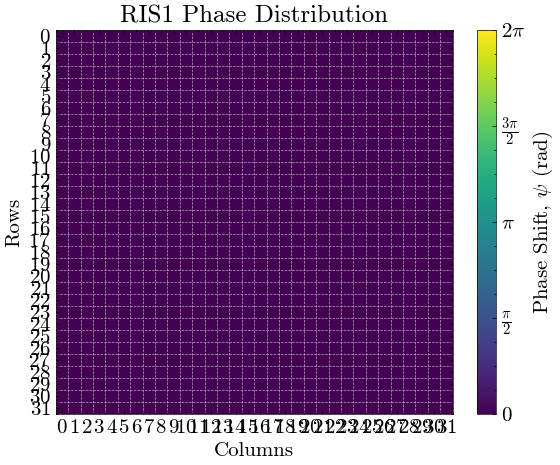

[9.81710781e-01 1.06616310e-06 8.30851244e-04]


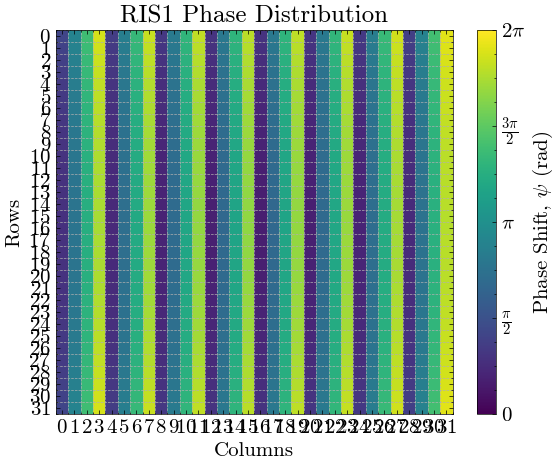

[2.38887271e-08 1.00000000e+00 6.64360048e-03]


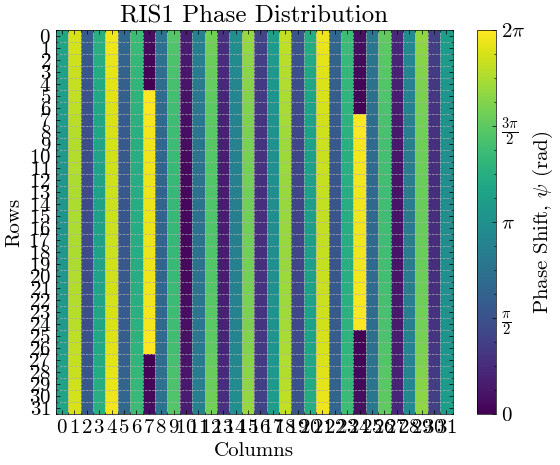

[8.43170766e-04 6.64360048e-03 1.00000000e+00]


In [3]:
max_bf = (ris.Nrow * ris.Ncol) ** 2

# Create antennas and channel
tx_pos = sph2cart([10, 0, 0])
tx_antenna = Antenna(tx_pos, 0)

rx_pos1 = sph2cart([10, 180, 30])
rx_antenna1 = Antenna(rx_pos1, 0)

rx_pos2 = sph2cart([10, 180, 45])
rx_antenna2 = Antenna(rx_pos2, 0)

rx_pos = np.array([[0, 0, 20], rx_pos1[0], rx_pos2[0]])

channel = tang_general_channel()

# Generate rx locations as a 2D map
ris.reset_ris()
ris.plot_phase_dist()
print(
    channel.phase_bf_multrx(tx_antenna=tx_antenna, rx_positions=rx_pos, ris=ris)
    / max_bf
)

channel.optimize(
    optimizer="direct_disc",
    mode="cont",
    tx_antenna=tx_antenna,
    rx_antenna=rx_antenna1,
    ris=ris,
)
ris.plot_phase_dist()
print(
    channel.phase_bf_multrx(tx_antenna=tx_antenna, rx_positions=rx_pos, ris=ris)
    / max_bf
)

channel.optimize(
    optimizer="direct_disc",
    mode="cont",
    tx_antenna=tx_antenna,
    rx_antenna=rx_antenna2,
    ris=ris,
)
ris.plot_phase_dist()
print(
    channel.phase_bf_multrx(tx_antenna=tx_antenna, rx_positions=rx_pos, ris=ris)
    / max_bf
)

In [4]:
# xlim = [-15, 15]
# zlim = [0, 20]
# Nx = 100
# Nz = 100

# ris.reset_ris()
# channel.plot_phase_bf_2d_map(tx_antenna=tx_antenna, ris=ris, ax1lim=xlim, ax2lim=zlim, Nax1=Nx, Nax2=Nz, plane='xz')

# channel.optimize(optimizer='direct_disc', mode='cont', tx_antenna=tx_antenna, rx_antenna=rx_antenna1, ris=ris)
# channel.plot_phase_bf_2d_map(tx_antenna=tx_antenna, ris=ris, ax1lim=xlim, ax2lim=zlim, Nax1=Nx, Nax2=Nz, plane='xz')

# channel.optimize(optimizer='direct_disc', mode='cont', tx_antenna=tx_antenna, rx_antenna=rx_antenna2, ris=ris)
# channel.plot_phase_bf_2d_map(tx_antenna=tx_antenna, ris=ris, ax1lim=xlim, ax2lim=zlim, Nax1=Nx, Nax2=Nz, plane='xz')



In [5]:
# xlim = [-15, 15]
# zlim = [0, 20]
# Nx = 100
# Nz = 100

# ris.reset_ris()
# channel.plot_path_gain_2d_map(tx_antenna=tx_antenna, rx_antenna=rx_antenna1, ris=ris, ax1lim=xlim, ax2lim=zlim, Nax1=Nx, Nax2=Nz, plane='xz', vmin=-160, vmax=-80)

# channel.optimize(optimizer='direct_disc', mode='cont', tx_antenna=tx_antenna, rx_antenna=rx_antenna1, ris=ris)
# channel.plot_path_gain_2d_map(tx_antenna=tx_antenna, rx_antenna=rx_antenna1, ris=ris, ax1lim=xlim, ax2lim=zlim, Nax1=Nx, Nax2=Nz, plane='xz', vmin=-160, vmax=-80)

# channel.optimize(optimizer='direct_disc', mode='cont', tx_antenna=tx_antenna, rx_antenna=rx_antenna2, ris=ris)
# channel.plot_path_gain_2d_map(tx_antenna=tx_antenna, rx_antenna=rx_antenna2, ris=ris, ax1lim=xlim, ax2lim=zlim, Nax1=Nx, Nax2=Nz, plane='xz', vmin=-160, vmax=-80)


In [6]:
# ris.reset_ris()
# channel.plot_phase_bf_dist(tx_antenna=tx_antenna, ris=ris, phi_deg=0, theta_deg=0, r1=0, r2=20, Nr=1000)

# channel.optimize(optimizer='direct_disc', mode='cont', tx_antenna=tx_antenna, rx_antenna=rx_antenna1, ris=ris)
# channel.plot_phase_bf_dist(tx_antenna=tx_antenna, ris=ris, phi_deg=180, theta_deg=30, r1=0, r2=20, Nr=1000)

# channel.optimize(optimizer='direct_disc', mode='cont', tx_antenna=tx_antenna, rx_antenna=rx_antenna2, ris=ris)
# channel.plot_phase_bf_dist(tx_antenna=tx_antenna, ris=ris, phi_deg=180, theta_deg=45, r1=0, r2=20, Nr=1000)

In [7]:
# ris.reset_ris()
# channel.plot_path_gain_dist(tx_antenna=tx_antenna, rx_antenna=rx_antenna1, ris=ris, phi_deg=0, theta_deg=0, r1=0.01, r2=20, Nr=1000, vmin=-110, vmax=-70)

# channel.optimize(optimizer='direct_disc', mode='cont', tx_antenna=tx_antenna, rx_antenna=rx_antenna1, ris=ris)
# channel.plot_path_gain_dist(tx_antenna=tx_antenna, rx_antenna=rx_antenna1, ris=ris, phi_deg=180, theta_deg=30, r1=0.01, r2=20, Nr=1000, vmin=-110, vmax=-70)

# channel.optimize(optimizer='direct_disc', mode='cont', tx_antenna=tx_antenna, rx_antenna=rx_antenna2, ris=ris)
# channel.plot_path_gain_dist(tx_antenna=tx_antenna, rx_antenna=rx_antenna2, ris=ris, phi_deg=180, theta_deg=45, r1=0.01, r2=20, Nr=1000, vmin=-110, vmax=-70)

In [8]:
# ris.reset_ris()
# channel.plot_phase_bf_angle_2d_map(tx_antenna=tx_antenna, ris=ris, r=10, Nr=100)

# channel.optimize(optimizer='direct_disc', mode='cont', tx_antenna=tx_antenna, rx_antenna=rx_antenna1, ris=ris)
# channel.plot_phase_bf_angle_2d_map(tx_antenna=tx_antenna, ris=ris, r=10, Nr=100)

# channel.optimize(optimizer='direct_disc', mode='cont', tx_antenna=tx_antenna, rx_antenna=rx_antenna2, ris=ris)
# channel.plot_phase_bf_angle_2d_map(tx_antenna=tx_antenna, ris=ris, r=10, Nr=100)

In [9]:
# ris.reset_ris()
# channel.plot_path_gain_angle_2d_map(tx_antenna=tx_antenna, rx_antenna=rx_antenna1, ris=ris, r=10, Nr=100, vmin=-100, vmax=-90)

# channel.optimize(optimizer='direct_disc', mode='cont', tx_antenna=tx_antenna, rx_antenna=rx_antenna1, ris=ris)
# channel.plot_path_gain_angle_2d_map(tx_antenna=tx_antenna, rx_antenna=rx_antenna1, ris=ris, r=10, Nr=100, vmin=-100, vmax=-90)

# channel.optimize(optimizer='direct_disc', mode='cont', tx_antenna=tx_antenna, rx_antenna=rx_antenna2, ris=ris)
# channel.plot_path_gain_angle_2d_map(tx_antenna=tx_antenna, rx_antenna=rx_antenna1, ris=ris, r=10, Nr=100, vmin=-100, vmax=-90)


In [ ]:
# ris.reset_ris()
# channel.plot_phase_bf_angle_3d(tx_antenna=tx_antenna, ris=ris, r=10, Nr=100)

# channel.optimize(optimizer='direct_disc', mode='cont', tx_antenna=tx_antenna, rx_antenna=rx_antenna1, ris=ris)
# channel.plot_phase_bf_angle_3d(tx_antenna=tx_antenna, ris=ris, r=10, Nr=100)

# channel.optimize(optimizer='direct_disc', mode='cont', tx_antenna=tx_antenna, rx_antenna=rx_antenna2, ris=ris)
# channel.plot_phase_bf_angle_3d(tx_antenna=tx_antenna, ris=ris, r=10, Nr=100)